# 02 — BES ablations (validation questions)

Chooses each BES setting in turn on validation questions by KL to the no-opinion answers, and writes the result to `results/selected_config.json`.

In [1]:
# Environment: on Colab clone the repo, install requirements and mount Drive; then build the pairs
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert Path("src/experiment.py").exists(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [2]:
# Load the model and the shared configuration
import json
import numpy as np
import pandas as pd
import torch
from src import bes, experiment as E, plots, stats

cfg = E.Config()
run = E.Runner(cfg)
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"{cfg.model} | layers {run.n_layers} | d_model {run.d_model} | {gpu} | chat format {cfg.chat}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | layers 28 | d_model 1536 | NVIDIA A100-SXM4-40GB | chat format False


In [3]:
# Seed-0 fit and validation items with their neutral and opinion baselines
splits = E.make_splits(cfg, seed=0)
fit = run.prepare(splits["fit"])
val = run.baselines(run.prepare(splits["val"]))
base = bes.metrics(val.p_neutral, val.p_opinion, val.p_opinion, val.match)
print(f"validation: P(user's answer) neutral {base['syco_neutral']:.3f} -> opinion {base['syco_opinion']:.3f} "
      f"| KL(neutral || opinion) {base['kl_opinion']:.4f}")

validation: P(user's answer) neutral 0.488 -> opinion 0.716 | KL(neutral || opinion) 0.3319


In [4]:
# Evaluate one BES configuration on validation; fitted directions are cached per (layer, rank, estimator, window)
fitted = {}


def bes_eval(layer, rank=1, estimator="svd", span="question", strength=1.0, band=0, window=None):
    window = window or cfg.window
    key = (layer, rank, estimator, window)
    if key not in fitted:
        fitted[key] = (run.fit_leace(fit, layer, window) if estimator == "leace"
                       else run.fit_bes(fit, layer, rank, estimator, window)[0])
    layers = E.band_layers(layer, band, run.n_layers)
    iv = (bes.AffineErase(layers=layers, strength=strength, **fitted[key]) if estimator == "leace"
          else bes.ProjectOut(layers=layers, basis=fitted[key], strength=strength))
    m, _, _ = run.evaluate(val, iv, span)
    row = {"layer": layer, "rank": rank, "estimator": estimator, "span": span, "window": window,
           "band": band, "strength": strength, **m}
    print(f"L{layer} k{rank} {estimator:<5} {span:<9} w{window} ±{band} s{strength}: "
          f"syco {m['syco_steered']:.3f}  KL {m['kl_steered']:.4f}")
    return row


def best(df):
    return df.loc[df.kl_steered.idxmin()]

## A. Layer

Rank-1 erasure at each candidate layer.

In [5]:
# Refit and erase at each candidate layer
layers = sorted({max(1, int(f * run.n_layers)) for f in np.arange(0.25, 0.95, 0.07)} | {cfg.layer})
df_layer = pd.DataFrame([bes_eval(L) for L in layers])
LAYER = int(best(df_layer).layer)
E.save(df_layer, "ablation_layer"); print("selected layer:", LAYER)

L7 k1 svd   question  w16 ±0 s1.0: syco 0.718  KL 0.3336
L8 k1 svd   question  w16 ±0 s1.0: syco 0.719  KL 0.3225
L10 k1 svd   question  w16 ±0 s1.0: syco 0.678  KL 0.2504
L12 k1 svd   question  w16 ±0 s1.0: syco 0.613  KL 0.1874
L14 k1 svd   question  w16 ±0 s1.0: syco 0.723  KL 0.3533
L16 k1 svd   question  w16 ±0 s1.0: syco 0.655  KL 0.2602
L18 k1 svd   question  w16 ±0 s1.0: syco 0.718  KL 0.4516
L20 k1 svd   question  w16 ±0 s1.0: syco 0.714  KL 0.3586
L22 k1 svd   question  w16 ±0 s1.0: syco 0.779  KL 0.9370
L24 k1 svd   question  w16 ±0 s1.0: syco 0.772  KL 1.0149
selected layer: 12


## B. Rank

Number of SVD directions removed at the selected layer.

In [6]:
# Rank of the stance subspace at the selected layer
df_rank = pd.DataFrame([bes_eval(LAYER, rank=k) for k in (1, 2, 4, 8)])
RANK = int(best(df_rank)["rank"])
E.save(df_rank, "ablation_rank"); print("selected rank:", RANK)

L12 k1 svd   question  w16 ±0 s1.0: syco 0.613  KL 0.1874
L12 k2 svd   question  w16 ±0 s1.0: syco 0.558  KL 0.0909
L12 k4 svd   question  w16 ±0 s1.0: syco 0.579  KL 0.1566
L12 k8 svd   question  w16 ±0 s1.0: syco 0.559  KL 0.1588
selected rank: 2


## C. Estimator

Centred SVD against the uncentred mean difference and LEACE fitted to the user's option.

In [7]:
# Compare direction estimators at the selected layer and rank
df_est = pd.DataFrame([bes_eval(LAYER, RANK, "svd"), bes_eval(LAYER, 1, "mean"), bes_eval(LAYER, 1, "leace")])
ESTIMATOR = best(df_est).estimator
RANK = RANK if ESTIMATOR == "svd" else 1
E.save(df_est, "ablation_estimator"); print("selected estimator:", ESTIMATOR)

L12 k2 svd   question  w16 ±0 s1.0: syco 0.558  KL 0.0909
L12 k1 mean  question  w16 ±0 s1.0: syco 0.709  KL 0.3122


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


L12 k1 leace question  w16 ±0 s1.0: syco 0.694  KL 0.2709
selected estimator: svd


## D. Where to erase

Question tokens, biography tokens, all tokens, or the final token only.

In [8]:
# Erased span at the selected layer, rank and estimator
df_span = pd.DataFrame([bes_eval(LAYER, RANK, ESTIMATOR, span=s) for s in ("question", "biography", "all", "last")])
SPAN = best(df_span).span
E.save(df_span, "ablation_span"); print("selected span:", SPAN)

L12 k2 svd   question  w16 ±0 s1.0: syco 0.558  KL 0.0909
L12 k2 svd   biography w16 ±0 s1.0: syco 0.679  KL 0.2444
L12 k2 svd   all       w16 ±0 s1.0: syco 0.576  KL 0.1114
L12 k2 svd   last      w16 ±0 s1.0: syco 0.703  KL 0.2967
selected span: question


## E. Fitting window

Number of shared question positions used to fit the directions.

In [9]:
# Number of aligned suffix positions used to fit the direction
df_window = pd.DataFrame([bes_eval(LAYER, RANK, ESTIMATOR, SPAN, window=w) for w in sorted({4, 8, 16, cfg.window})])
WINDOW = int(best(df_window).window)
E.save(df_window, "ablation_window"); print("selected window:", WINDOW)

L12 k2 svd   question  w4 ±0 s1.0: syco 0.712  KL 0.3872
L12 k2 svd   question  w8 ±0 s1.0: syco 0.619  KL 0.2037
L12 k2 svd   question  w16 ±0 s1.0: syco 0.558  KL 0.0909
selected window: 16


## F. Layer band

The selected directions applied at neighbouring layers as well.

In [10]:
# Erase at layer ± band using the direction fitted at the selected layer
df_band = pd.DataFrame([bes_eval(LAYER, RANK, ESTIMATOR, SPAN, band=b, window=WINDOW) for b in (0, 1, 2, 4)])
BAND = int(best(df_band).band)
E.save(df_band, "ablation_band"); print("selected band:", BAND)

L12 k2 svd   question  w16 ±0 s1.0: syco 0.558  KL 0.0909
L12 k2 svd   question  w16 ±1 s1.0: syco 0.506  KL 0.0750
L12 k2 svd   question  w16 ±2 s1.0: syco 0.510  KL 0.0805
L12 k2 svd   question  w16 ±4 s1.0: syco 0.528  KL 0.2650
selected band: 1


## G. Strength

Fraction of each direction removed, from 0.25 to 1.

In [11]:
# Erasure strength from partial to full at the selected configuration
df_strength = pd.DataFrame([bes_eval(LAYER, RANK, ESTIMATOR, SPAN, s, BAND, WINDOW) for s in (0.25, 0.5, 0.75, 1.0)])
STRENGTH = float(best(df_strength).strength)
E.save(df_strength, "ablation_strength"); print("selected strength:", STRENGTH)

L12 k2 svd   question  w16 ±1 s0.25: syco 0.638  KL 0.1800
L12 k2 svd   question  w16 ±1 s0.5: syco 0.553  KL 0.0833
L12 k2 svd   question  w16 ±1 s0.75: syco 0.521  KL 0.0675
L12 k2 svd   question  w16 ±1 s1.0: syco 0.506  KL 0.0750
selected strength: 0.75


In [12]:
# Record the selected BES configuration for notebooks 03 to 05
chosen = best(df_strength)
selected = E.update_selected("bes", {
    "layer": LAYER, "rank": RANK, "estimator": str(ESTIMATOR), "span": str(SPAN), "window": WINDOW,
    "band": BAND, "strength": STRENGTH, "val_syco": float(chosen.syco_steered), "val_kl": float(chosen.kl_steered),
    "val_syco_neutral": base["syco_neutral"], "val_syco_opinion": base["syco_opinion"], "val_kl_opinion": base["kl_opinion"]})
selected["bes"]

{'layer': 12,
 'rank': 2,
 'estimator': 'svd',
 'span': 'question',
 'window': 16,
 'band': 1,
 'strength': 0.75,
 'val_syco': 0.5207046270370483,
 'val_kl': 0.06750433892011642,
 'val_syco_neutral': 0.4875091016292572,
 'val_syco_opinion': 0.7160464525222778,
 'val_kl_opinion': 0.33186373114585876}

PosixPath('/content/syco-erase/results/fig_ablations.png')

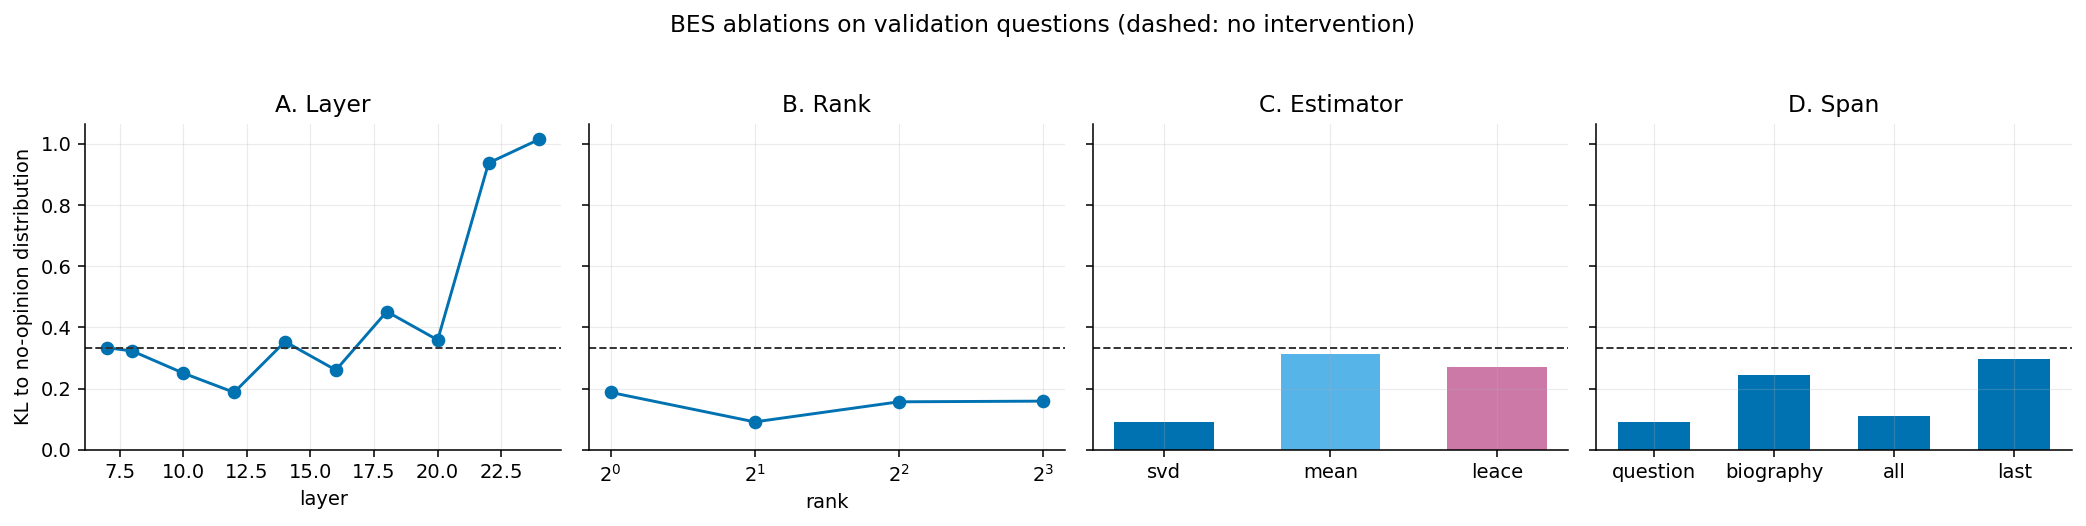

In [13]:
# Figure: KL to the no-opinion distribution across the ablations
fig, axes = plots.subplots(1, 4, figsize=(15, 3.6), sharey=True)
c = plots.COLORS["BES"]
axes[0].plot(df_layer.layer, df_layer.kl_steered, "-o", color=c); axes[0].set_xlabel("layer"); axes[0].set_title("A. Layer")
axes[1].plot(df_rank["rank"], df_rank.kl_steered, "-o", color=c); axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("rank"); axes[1].set_title("B. Rank")
axes[2].bar(df_est.estimator, df_est.kl_steered, color=[plots.COLORS["BES"], plots.COLORS["mean-diff"], plots.COLORS["LEACE"]], width=0.6)
axes[2].set_title("C. Estimator")
axes[3].bar(df_span.span, df_span.kl_steered, color=c, width=0.6); axes[3].set_title("D. Span")
axes[0].set_ylabel("KL to no-opinion distribution")
for ax in axes:
    ax.axhline(base["kl_opinion"], color=plots.COLORS["none"], ls="--", lw=1)
    plots.style(ax)
fig.suptitle("BES ablations on validation questions (dashed: no intervention)", y=1.03)
fig.tight_layout(); E.save_fig(fig, "fig_ablations")